In [171]:
%load_ext autoreload
%autoreload 2
%aimport
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Modules to reload:
all-except-skipped

Modules to skip:



In [172]:
import os
import sys
nb_dir = os.path.dirname(os.path.split(os.getcwd())[0])
if nb_dir not in sys.path:
    sys.path.append(nb_dir)

In [173]:
from tqdm import tqdm_notebook as tqdm
import pandas as pd
from turicreate import SFrame, load_sframe
from pathlib import Path
import turicreate.aggregate as agg
import numpy as np

In [174]:
from unidecode import unidecode
import spacy
from collections import defaultdict
from itertools import chain
nlp = spacy.load('en_core_web_lg', disable=['parser', 'tagger', 'textcat'])

In [238]:
diseases_id= load_sframe("Data/diseases_id.csv")
disease_names= load_sframe("Data/disease_names.csv")

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/diseases_id.csv

Parsing completed. Parsed 100 lines in 0.067182 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[str,int]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/diseases_id.csv

Parsing completed. Parsed 588 lines in 0.05013 secs.

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/disease_names.csv

Parsing completed. Parsed 100 lines in 0.048589 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[int,str]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/disease_names.csv

Parsing completed. Parsed 334 lines in 0.054724 secs.

## Pre-Processing

In [239]:
from ScienceDynamics.datasets.microsoft_academic_graph import MicrosoftAcademicGraph
from ScienceDynamics.config.configs import DATASETS_BASE_DIR
mag = MicrosoftAcademicGraph(DATASETS_BASE_DIR / "MicrosoftAcademicGraph.zip")

In [240]:
diseases_mag = load_sframe("Data/mag/diseases_mag.sframe")

In [241]:
paper_ids = diseases_mag["Paper ID"]

In [242]:
def get_gpe(uni):
    doc = nlp(uni)

    return [ent.text for ent in doc.ents if ent.label_=="GPE"]

In [243]:
paper_author_aff = mag.paper_author_affiliations

In [244]:
paper_author_aff = paper_author_aff.filter_by(paper_ids,"Paper ID")

In [245]:
paper_author_aff.save("Data/mag/paper_author_aff.sframe")

In [77]:
paper_author_aff = load_sframe("Data/mag/paper_author_aff.sframe")

In [246]:
mag_affiliation = set(paper_author_aff["Original affiliation name"])

In [247]:
len(set(paper_author_aff["Normalized affiliation name"]))

6946

In [256]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]
        

        
        
def get_entites(uni):
    d = defaultdict(list)
    doc = nlp(uni)
    for ent in doc.ents:
        d[ent.label_].append(ent.text)
    return uni , d

import concurrent
max_workers = 12
res = []
# with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
#     for e in tqdm(executor.map(get_entites, locations_raw), total=len(locations_raw)):
#         res.append(e)

                
batch_size = 10000

for batch in tqdm(chunks(list(mag_affiliation), batch_size), total=len(mag_affiliation)//batch_size):
    with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
        for e in executor.map(get_entites, batch):
            res.append(e)


In [257]:
from pandas.io.json import json_normalize

df2 = json_normalize( pd.DataFrame(res)[1])

In [258]:
mag_universities=df2[["ORG","GPE"]]

In [259]:
mag_universities["raw"] = pd.DataFrame(res)[0]

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [260]:
mag_universities.index = mag_universities["raw"]

In [261]:
mag_universities = mag_universities.iloc[1:]

In [262]:
for row in mag_universities.loc[mag_universities.GPE.isnull(), 'GPE'].index:
    mag_universities.at[row, 'GPE'] = []

In [263]:
dd = defaultdict(list)
dd = mag_universities["GPE"].to_dict(dd)

In [ ]:
paper_author_aff["GPE"] = paper_author_aff["Original affiliation name"].apply(lambda x: dd[x])

In [ ]:
import pycountry
import  functools
# @functools.lru_cache(maxsize=8048)
def get_iso(txt):
    try:
        return pycountry.countries.search_fuzzy(txt)[0].alpha_2
    except:
        pass
    return ""

In [ ]:
paper_author_aff["iso"] = paper_author_aff["GPE"].apply(lambda locs: [ get_iso(x) for x in locs])

In [ ]:
paper_author_aff.save("Data/mag/paper_author_aff2.sframe")

In [81]:
paper_author_aff = load_sframe("Data/mag/paper_author_aff2.sframe")

In [273]:
paper_author_aff["iso"] = paper_author_aff["iso"].apply(lambda x: list(set(x)))

In [274]:
affiliation_iso = paper_author_aff[paper_author_aff["iso"]!=[]][["iso", "Normalized affiliation name"]]

In [275]:
affiliation_iso = affiliation_iso.stack("iso",new_column_name="iso")

In [276]:
affiliation_iso = affiliation_iso[affiliation_iso["iso"]!=""]

In [277]:
affiliation_iso = affiliation_iso.groupby(["Normalized affiliation name", "iso"],[agg.COUNT()])

In [278]:
affiliation_iso[affiliation_iso["Normalized affiliation name"]=="university of guelph"]

Normalized affiliationname ...,iso,Count
university of guelph,GB,54
university of guelph,US,1
university of guelph,CA,500
university of guelph,EG,1


In [279]:
affiliation_iso = affiliation_iso.groupby(["Normalized affiliation name"],{"Count":agg.MAX("Count"), "iso": agg.ARGMAX("Count", "iso")})

In [280]:
affiliation_iso.save("Data/mag/affiliation_iso.sframe")

In [281]:
affiliation_iso = {line["Normalized affiliation name"]: line["iso"] for line in affiliation_iso}

In [282]:
affiliation_iso = defaultdict(str, affiliation_iso)

In [283]:
paper_author_aff["iso"] = paper_author_aff["Normalized affiliation name"].apply(lambda x: affiliation_iso[x])

In [284]:
paper_author_aff[paper_author_aff["Normalized affiliation name"]=='alnylam pharmaceuticals']

Paper ID,Author ID,Affiliation ID,Original affiliation name,Normalized affiliationname ...,Author sequence number
77D5E5DC,7E9C945C,08A945A5,"Alnylam Pharmaceuticals,Inc., 300 Third Street, ...",alnylam pharmaceuticals,11
752292A1,7E9C945C,08A945A5,"Alnylam Pharmaceuticals,Cambridge, Massachuse ...",alnylam pharmaceuticals,6
80398F99,762AB3ED,08A945A5,"Alnylam Pharmaceuticals,Cambridge, MA 02142, USA ...",alnylam pharmaceuticals,6
80398F99,7FC7D7F5,08A945A5,"Alnylam Pharmaceuticals,Cambridge, MA 02142, USA ...",alnylam pharmaceuticals,5
5B346788,6E15B2EC,08A945A5,"California Institute ofMolecular Medicine, ...",alnylam pharmaceuticals,3
77D5E5DC,77872022,08A945A5,"Alnylam Pharmaceuticals,Inc., 300 Third Street, ...",alnylam pharmaceuticals,6
77D5E5DC,777B35E6,08A945A5,"Alnylam Pharmaceuticals,Inc., 300 Third Street, ...",alnylam pharmaceuticals,4
7600B0F0,76B22D53,08A945A5,"Alnylam Pharmaceuticals,Cambridge, MA ...",alnylam pharmaceuticals,7
78D66727,084B6CD6,08A945A5,"Alnylam Pharmaceuticals,300 Third Street, ...",alnylam pharmaceuticals,8
77D5E5DC,7666049C,08A945A5,"Alnylam Pharmaceuticals,Inc., 300 Third Street, ...",alnylam pharmaceuticals,8


In [197]:
paper_author_aff.save("Data/mag/paper_author_aff.sframe")

## Author Country

In [198]:
paper_author_aff = load_sframe("Data/mag/paper_author_aff.sframe")

In [285]:
paper_author_aff = paper_author_aff[paper_author_aff["GPE"]!=[]]

In [286]:
x = paper_author_aff[["Paper ID","Author ID", "iso"]].unstack(["Author ID", "iso"])

In [287]:
x["num_countries"] = x["Dict of Author ID_iso"].apply(lambda x: len({v for k,v in x.items() if v!=""  }))

In [288]:
try:
    diseases_mag= diseases_mag.remove_columns(["Dict of Author ID_iso","num_countries"])
except:
    pass

In [289]:
diseases_mag = diseases_mag.join(x, on={"Paper ID":"Paper ID"})

In [290]:
diseases_mag.save("Data/mag/diseases_countries.sframe")

In [252]:
diseases_mag = load_sframe("Data/mag/diseases_countries.sframe")

In [291]:
diseases_mag = diseases_mag[diseases_mag["num_countries"] > 0]

In [292]:
diseases_mag.groupby("id",operations={"disease": agg.SELECT_ONE("disease"),"num_countries":agg.AVG("num_countries"), "count":agg.COUNT() }).sort("num_countries",False).save("output/author_counter.csv")

In [293]:
df = diseases_mag.groupby("Paper publish year",operations={"Average Distinct Countries":agg.AVG("num_countries"), "count":agg.COUNT() }).sort("Paper publish year",False)

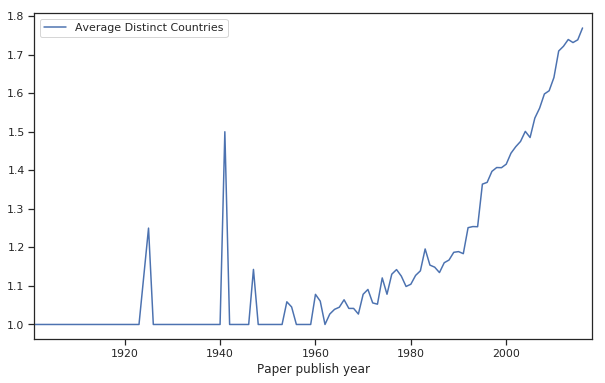

In [294]:
df.to_dataframe().plot(x="Paper publish year", y="Average Distinct Countries", xlim=(1901,2018), figsize=(10,6))

In [295]:
df.save("output/Collab/world_collab.csv")

In [296]:
df2 = diseases_mag.groupby(["id", "Paper publish year"],operations={"disease": agg.SELECT_ONE("disease"),"num_countries":agg.AVG("num_countries"), "count":agg.COUNT() }).sort("Paper publish year",False)

In [297]:
# df2 = df2.join(disease_names,{"id":"id"})

In [298]:
df2 = df2.rename({"Paper publish year":"Year","num_countries":"Averge Number of Countries"})

In [299]:
df2 = df2.rename({"disease":"Disease"})

In [300]:
df2 = df2.sort(["Disease", "Year"])

In [301]:
df2[df2["id"]==3].sort("count", False)

Year,id,Disease,Averge Number ofCountries ...,count
2008,3,plesiomonas,1.0,5
2007,3,plesiomonas,1.25,4
2000,3,plesiomonas,1.6666666666666667,3
2006,3,plesiomonas,1.3333333333333333,3
2005,3,plesiomonas,2.0,2
1980,3,plesiomonas,2.0,1
1984,3,plesiomonas,1.0,1
1985,3,plesiomonas,2.0,1
1989,3,plesiomonas,1.0,1
1992,3,plesiomonas,1.0,1


In [302]:
df_count = df2[df2["count"] >5].groupby("id",{"Count":agg.COUNT()})

In [303]:
df_count = df_count[df_count["Count"] > 5]

In [304]:
df3 = df2.join(df_count,{"id":"id"})

In [305]:
df3 = df3.sort(["Disease","Year"])

In [306]:
df3.save("output/Collab/countries.csv")

In [307]:
df3_smooth= df3[["Disease","Average Number of Countries"]].to_dataframe().groupby("Disease").rolling(5).sum()

In [308]:
df3_smooth = df3_smooth.reset_index()

In [309]:
df3_smooth["Year"] = df3.to_dataframe()["Year"]

In [310]:
df3_smooth["Average Number of Countries"] = df3_smooth["Average Number of Countries"]/5

In [311]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_d(sf_corr):
    for data in sf_corr.groupby("Disease"):
        if len(data[1]) >5:
            yield data[1].sort_values("Year")

In [312]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")
def create_gird(df, col, hue,x,y):

    # Initialize a grid of plots with an Axes for each walk
    grid = sns.FacetGrid(df, col=col, hue=hue, palette="tab20c",
                         col_wrap=5, height=4.5)

    # Draw a horizontal line to show the starting point
    grid.map(plt.axhline, y=0, ls=":", c=".5")

    # Draw a line plot to show the trajectory of each random walk
    grid.map(plt.plot, x, y)

    # Adjust the tick positions and labels
    # grid.set(xticks=np.arange(5), yticks=[-3, 3],
    #          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

    # Adjust the arrangement of the plots
    grid.fig.tight_layout(w_pad=1)
    return grid

In [328]:
df3_smooth = df3_smooth.rename(columns={"Averge Number of Countries":"Average Number of Countries"})

In [329]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Collab/countries.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(df3_smooth))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "Average Number of Countries")
#         plt.title('Page')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

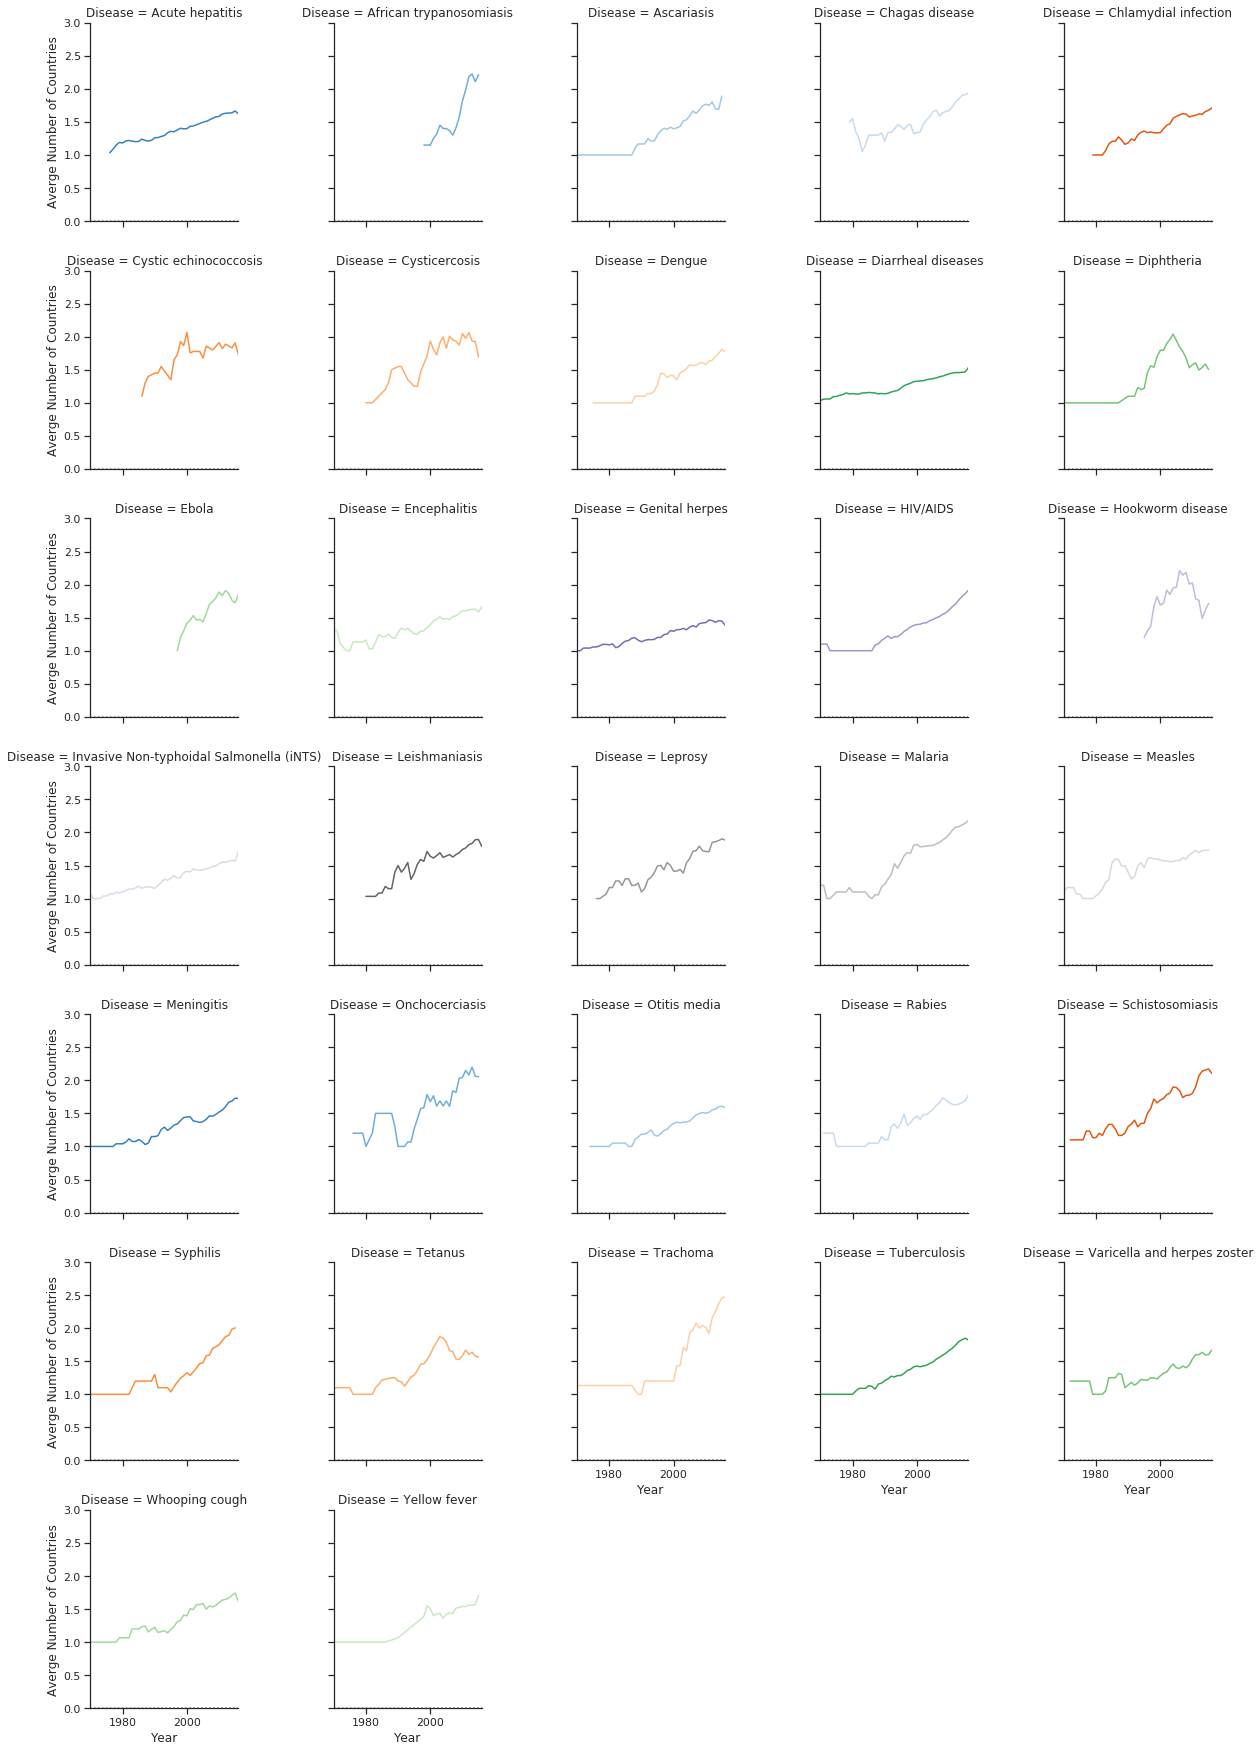

In [278]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")

# df2 = df2.to_dataframe()
# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(df3_smooth, col="Disease",hue="Disease", palette="tab20c",
                     col_wrap=5, height=3.5)

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "Averge Number of Countries")

# Adjust the tick positions and labels
grid.set(xlim=(1970, 2016), ylim=(0, 3))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

### Pair Colab

In [330]:
diseases_mag["countries"] = diseases_mag["Dict of Author ID_iso"].apply(lambda x: [v for v in set(x.values()) if v!=""])

In [331]:
diseases_mag2 = diseases_mag[diseases_mag["num_countries"] >1]

In [332]:
diseases_mag2["countries"] = diseases_mag2["countries"].apply(lambda x: sorted(x))

In [333]:
from itertools import combinations

In [334]:
diseases_mag2["con_pairs"] = diseases_mag2["countries"].apply(lambda x: list(combinations(x, 2)))


In [335]:
diseases_mag3 = diseases_mag2.stack("con_pairs", new_column_name="con_pairs")

In [336]:
diseases_mag_pairs = diseases_mag3.groupby(["disease","Paper publish year","con_pairs"],agg.COUNT)

In [337]:
diseases_mag_pairs.sort("Count",False)

Paper publish year,con_pairs,disease,Count
2011,"[FR, US]",hiv,347
2013,"[FR, US]",hiv,336
2012,"[FR, US]",hiv,315
2010,"[FR, US]",hiv,304
2009,"[FR, US]",hiv,285
2014,"[FR, US]",hiv,266
2008,"[FR, US]",hiv,259
2007,"[FR, US]",hiv,221
2006,"[FR, US]",hiv,171
2011,"[FR, GB]",hiv,148


In [338]:
def convert_to_barchart_format(sf,x, year_columen="Year", count_column="count",  year_range=(1786,2019)):
    year_sf = SFrame()
    year_sf[year_columen] = np.linspace(year_range[0],year_range[1],year_range[1]-year_range[0]+1).tolist()
    year_sf[year_columen] = year_sf[year_columen].astype(int)
    res_sf = SFrame()
    for d in tqdm(sf[x].unique()):
        temp_sf = SFrame()
        temp_sf[x] = [d]*len(year_sf)
        temp_sf[year_columen] = year_sf[year_columen]
        res_sf = res_sf.append(temp_sf)
    sf = sf.join(res_sf,how="right").sort(year_columen)
    sf = sf.fillna(count_column,0)
    df = sf.to_dataframe()
    df = df.sort_values([x,year_columen])
    df['value'] = df.groupby([x])[count_column].cumsum()
    df["lastValue"] = df.groupby([x])["value"].shift(1)
    df = df.fillna(0)
    df["rank"] =df.groupby([year_columen])["value"].rank(ascending=False)
    return df.rename({x:"name", year_columen: "year",count_column:"count"}, axis=1)[["year","name","value","lastValue","rank"]]

In [339]:
mag_pairs = diseases_mag_pairs.groupby(["Paper publish year","con_pairs"],{"count": agg.SUM("Count")})

In [340]:
mag_pairs["Collabs"] = mag_pairs["con_pairs"].apply(lambda x: ",".join(x))

In [341]:
max_year = mag_pairs["Paper publish year"].max()
min_year = mag_pairs["Paper publish year"].min()

In [342]:
mag_pairs = mag_pairs.rename({"Paper publish year": "year"})

In [343]:
mag_pairs

year,con_pairs,count,Collabs
2012,"[LA, US]",1,"LA,US"
1995,"[AT, US]",3,"AT,US"
2015,"[BR, CN]",4,"BR,CN"
1992,"[FR, MD]",3,"FR,MD"
2010,"[IT, TH]",2,"IT,TH"
2003,"[ES, GB]",2,"ES,GB"
1995,"[GB, IE]",2,"GB,IE"
2009,"[AR, ES]",2,"AR,ES"
1992,"[NL, SE]",1,"NL,SE"
1997,"[GM, ZM]",3,"GM,ZM"


In [344]:
pairs_barchart = convert_to_barchart_format(mag_pairs, "Collabs", "year", "count",(min_year, max_year))

In [345]:
pairs_barchart[["year","name","value","lastValue","rank"]].to_csv("output/Collab/pairs_barchart.csv", index=False)

In [237]:
diseases_pubmed = load_sframe("Data/pubmed/diseases_pubmed.sframe")

In [5]:
import re
from unidecode import unidecode

In [133]:
diseases_pubmed = diseases_pubmed[diseases_pubmed["affiliations"]!=""]
diseases_pubmed["affiliations"] = diseases_pubmed["affiliations"].apply(lambda x: x.split(";"))
diseases_pubmed["affiliations"] = diseases_pubmed["affiliations"].apply(lambda x: [re.sub(r'\S*@\S*\s?','', i) for i in x])
diseases_pubmed["affiliations"] = diseases_pubmed["affiliations"].apply(lambda aff: [re.sub(r'[^A-Za-z0-9\s\,]+', '', unidecode(x)) for x in aff])

## Geolocation

In [7]:
def get_geolocation_map(geolocator, geolcoator_name):
    """
    Create a locations' data dict for each location that appear in SFrame locations column
    :param geolocator: geopy geolocator object
    :param geolcoator_name: the geolocator name
    :return: dict which each location data collected using the input gelocator
    :rtype: dict
    :note: Example for createing a geolocator
    from geopy import Bing
    b = Bing(BING_MAPS_API_KEY)
    self._create_locations_data_dict(b, "Bing")
    """
    d = {}

    loc_dict = Counter(locations)
    
    for loc, v in tqdm(loc_dict.most_common()):
        if loc in d:
            continue
            
        try:
            gcode = geolocator.geocode(loc)
            if gcode is not None:
                gcode = gcode.raw

            d[geolcoator_name][loc] = gcode
            time.sleep(1.2)  # sleep 1200 milisecs to not limit api limitations
        except GeocoderTimedOut:
            print("GeocoderTimedOut")
            time.sleep(5)
            pass
    return d

In [8]:
import functools

In [9]:
institution = SFrame.read_csv("Data/journals/ScimagoIR.csv",delimiter=";")
institution["Institution"] = institution["Institution"].apply(lambda x: x.replace(" *",""))
institutions = [l.lower() for l in institution["Institution"]]
institution_country = {l["Institution"].lower() : l["Country"] for l in institution}

@functools.lru_cache(maxsize=2048)
def match_inst(l):
    for i in institutions:
        if i in l.lower() or l.lower() in i:
            return i.title(), institution_country[i]
    return False


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/journals/ScimagoIR.csv

Parsing completed. Parsed 100 lines in 0.036701 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[int,str,str,str]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/journals/ScimagoIR.csv

Parsing completed. Parsed 6459 lines in 0.036736 secs.

In [159]:
from geopy.exc import GeocoderTimedOut , GeocoderNotFound, GeocoderServiceError
import time

In [ ]:
mapbox_map = {}
mapbox_map_i = {}
max_iso_iter = max_iso.iterrows()
for i, row in tqdm(max_iso_iter, total=len(max_iso)):
    loc= True
    try:
        if mapbox_map_i[i]:
            continue
    except:
        pass
    timeout = 1
    try:
        while 0<timeout<3:
            try:
                loc = mb.geocode(row["ORG Clean4"], country=row["iso"] )
                timeout = 0
            except  GeocoderTimedOut:
                timeout +=1
                time.sleep(5*timeout)
    except GeocoderServiceError:
        continue
    mapbox_map[row["ORG Clean4"]] = loc
    mapbox_map_i[i] = loc

In [10]:
from unidecode import unidecode
import spacy
from collections import defaultdict
from itertools import chain
res = []
nlp = spacy.load('en_core_web_lg', disable=['parser', 'tagger', 'textcat'])
    
def clean_orgs(o_list):
    black_list = ["Department", "Faculty" ,"Division" , "Centre", "Unit", "Laboratory", "Program", "Group", "Studies"]
    for b in black_list:
        o_list =  [ o for o in o_list if b not in o ]
    return o_list

def priorityze_keywords(uni):
    keywords =  ["University","Hospital", "Institut", "College", "School", "Medical Center"]
    for k in keywords:
        for u in uni:
            if k in u:
                return [u]
    return uni

def stndartize_affiliation(aff):
    inst = match_inst(aff)
    if inst:
        return inst
    doc = nlp(aff)
    orgs = [ent.text for ent in doc.ents if ent.label_ == "ORG"]
    orgs = list(chain.from_iterable([o.split(", ") for o in orgs ]))
    orgs = clean_orgs(orgs)
    if len(orgs) == 0:
        return False
    orgs =  orgs if len(orgs[-1])>2 else orgs[:-1]
    orgs = priorityze_keywords(orgs)
#     universities = universities[universities["ORG Clean"].str.len() != 0]
    if len(orgs) == 0:
        return False
    return orgs[-1]

def affiliations_to_location(aff):
    aff = stndartize_affiliation(aff)
    if not aff:
        return False
    try:
        if mapbox_map[aff] is not np.nan:
            return mapbox_map[aff]
    except KeyError:
        return False
    return False


In [235]:
diseases_pubmed["loc"] = diseases_pubmed["affiliations"].apply(lambda aff: [affiliations_to_location(x) for x in aff])

['Rockefeller University']


NameError: name 'mapbox_map' is not defined

In [11]:
from itertools import chain
# locations = list(chain.from_iterable(diseases_pubmed[diseases_pubmed["affiliations"]!=""]["affiliations"]))
locations_raw = list(chain.from_iterable(diseases_pubmed[diseases_pubmed["affiliations"]!=""]["affiliations"]))

locations_raw = set(locations_raw)
locations_raw = [l.strip() for l in locations_raw]

In [12]:
def match_inst(l):
    for i in institutions:
        if i in l.lower() or l.lower() in i:
            return l, i
    return False


In [13]:
import concurrent
max_workers = 12
institutions_map = {}
institutions_tuples = []
with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
    for res in tqdm(executor.map(match_inst, locations_raw), total=len(locations_raw)):
        if res:
            institutions_map[res[0]]=res[1]

In [14]:
from collections import defaultdict
institutions_d = defaultdict(str, institutions_map)

In [46]:
def get_entites(uni):
    d = defaultdict(list)
    temp_res = []
    for u in uni:
        doc = nlp(u)
        for ent in doc.ents:
            d[ent.label_].append(ent.text)
        temp_res.append(d)
    return temp_res
import concurrent
max_workers = 12
res = []
with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
    for entites in tqdm(executor.map(get_entites, diseases_pubmed["affiliations"]), total=len(diseases_pubmed["affiliations"])):
        res.append(entites)

In [15]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]
        

        
        
def get_entites(uni):
    d = defaultdict(list)
    doc = nlp(uni)
    for ent in doc.ents:
        d[ent.label_].append(ent.text)
    return uni , d

import concurrent
max_workers = 12
res = []
# with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
#     for e in tqdm(executor.map(get_entites, locations_raw), total=len(locations_raw)):
#         res.append(e)

                
batch_size = 10000

for batch in tqdm(chunks(locations_raw, batch_size), total=len(locations_raw)//batch_size):
    with concurrent.futures.ProcessPoolExecutor(max_workers=max_workers) as executor:
        for e in executor.map(get_entites, batch):
            res.append(e)


In [16]:
from pandas.io.json import json_normalize

df2 = json_normalize( pd.DataFrame(res)[1])

In [54]:
universities=df2[["ORG","GPE"]]

In [55]:
universities["raw"] = pd.DataFrame(res)[0]

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [56]:
len(universities)

745685

In [57]:
universities["uni"] = universities["raw"].apply(lambda x: institutions_d[x])

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [60]:
universities = universities.iloc[1:]

In [74]:
for row in universities.loc[universities.ORG.isnull(), 'ORG'].index:
    universities.at[row, 'ORG'] = []
for row in universities.loc[universities.GPE.isnull(), 'GPE'].index:
    universities.at[row, 'GPE'] = []

In [72]:
def match_inst(insts):
    for i in institutions:
        for l in insts:
            if i in l.lower() or l.lower() in i:
                return l, i
    return ("",)

In [ ]:
universities["uni"] = universities.progress_apply(lambda x: x["uni"] if x["uni"] else match_inst(x["ORG"])[0].lower(), axis=1)

In [58]:
institution_country = defaultdict(str, institution_country)

In [ ]:
universities["uni"] = universities["uni"].progress_apply(lambda x: x if x else "")

In [41]:
universities["country"] = universities["uni"].apply(lambda x: institution_country[x.lower()])

In [119]:
universities.to_csv("Data/universities.csv")

In [50]:
# universities["country"] = universities["country"].progress_apply(lambda x: x if x else "")

In [86]:
import pycountry
import  functools
# @functools.lru_cache(maxsize=8048)
def get_iso(txt):
    try:
        return pycountry.countries.search_fuzzy(txt)[0].alpha_2
    except:
        pass
    return ""


In [86]:
universities["country"] = universities["country"].progress_apply(lambda x: alpha_3_to_2(x))

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [ ]:
universities["iso"] = universities["GPE"].progress_apply(lambda locs: [ get_iso(x) for x in locs])

In [93]:
[][-1]

IndexError: list index out of range

In [102]:
 [i for i in ["",1,2,3,""] if i]

[1, 2, 3]

In [103]:
universities["iso"] = universities["iso"].progress_apply(lambda x: [i for i in x if i])

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [104]:
universities["iso2"] = universities["iso"].progress_apply(lambda x: x[-1] if x else "")

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [107]:
universities.iloc[31]

ORG        [Department of Oral Medicine and Radiology Dr ...
GPE                                           [Bihar, India]
raw        Department of Oral Medicine and Radiology Dr B...
uni                                                         
country                                                     
iso                                                 [IN, IN]
iso2                                                      IN
Name: 32, dtype: object

In [108]:
universities["country_join"] = universities.progress_apply(lambda x: x["country"] if x["country"] else x["iso2"] , axis=1)

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [116]:
universities["country_join"] = universities.progress_apply(lambda x: "GB" if "GB" in  x["iso"]  else x["country_join"]  , axis=1)

/storage/homedir/dima/miniconda3/envs/promed/lib/python3.6/site-packages/ipykernel_launcher.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  """Entry point for launching an IPython kernel.


In [128]:
uni_coutrtry = {line[1]["raw"]: line[1]["country_join"] for line in universities.iterrows()}

In [135]:
uni_coutrtry = defaultdict(str, uni_coutrtry)

In [169]:
universities["uni"] == ""

,ORG,GPE,raw,uni,country,iso,iso2,country_join
1,[Dongguan Eighth Peoples Hospital],"[Dongguan, China]","Dongguan Eighth Peoples Hospital, Dongguan, 52...",,,[CN],CN,CN
2,[DE],"[Suite 2E70, Newark, USA]",", 4755 OgletownStanton Road, Suite 2E70, Newar...",de,,[US],US,US
3,"[Centers for Disease Control and Prevention, M...","[Atlanta, USA]","Malaria Epidemiology Branch, Centers for Disea...",centers for disease control and prevention,US,[US],US,US
4,[Facultad de Ciencias Quimicas y Farmaceuticas...,[Chile],Departamento de Bioquimica y Biologia Molecula...,universidad de chile,CL,[CL],CL,CL
5,[Singapore General Hospital],[Singapore],"Singapore General Hospital, Singapore",singapore general hospital,SG,[SG],SG,SG
6,"[National Center for Communicable Diseases, Mi...","[Ulaanbaatar, Mongolia]","National Center for Communicable Diseases, Min...",ministry of health,MY,[MN],MN,MY
7,"[Institute for Food Safety and Hygiene, Vetsui...",[Zurich],"Institute for Food Safety and Hygiene, Vetsuis...",,,[CH],CH,CH
8,[University of Connecticut],[CT],"University of Connecticut, CT, USA",university of connecticut,,[ES],ES,ES
9,[Institut de Cancerologie],"[Villejuif, France]","Institut de Cancerologie Gustave Roussy, Ville...",,,[FR],FR,FR
10,"[Institute of Legal Medicine, University of Bo...",[Italy],"Institute of Legal Medicine, University of Bol...",,,[IT],IT,IT


In [171]:
uni_coutrtry["university of guelph".title()]

''

In [145]:
diseases_pubmed["aff_country"] = diseases_pubmed["affiliations"].apply(lambda affs: [uni_coutrtry[aff.strip()] for aff in affs])

In [151]:
diseases_pubmed["aff_country"] = diseases_pubmed["aff_country"].apply(lambda affs: [aff for aff in affs if aff])

In [152]:
x = diseases_pubmed[diseases_pubmed["aff_country"].apply(lambda x: len(x) >1 )]

In [154]:
diseases_pubmed["int_cloab"] = diseases_pubmed["aff_country"].apply(lambda affs: len(set(affs)))

In [158]:
diseases_pubmed.groupby("disease", operations={"int_cloab": agg.AVG("cint_cloab")})

disease,int_cloab
chlamydia,0.9822983984265208
varicella and herpeszoster ...,1.1489361702127663
meningitis,0.9621200189006128
trachoma,1.2494669509594876
meningococcemia,0.8749999999999996
gonococcal,0.9259615384615375
triple e,1.0
sleeping sickness,1.1322314049586768
hookworm disease,0.6896551724137929
leprosy,0.9280672268907549


In [34]:
from tqdm import tqdm


In [35]:
tqdm.pandas()

In [32]:
universities_sf = SFrame(universities)

In [130]:
universities_sf["iso"] = universities_sf["GPE"].apply(lambda x: get_iso(x))

In [135]:
universities_sf["country"] = universities_sf["country"].apply(lambda x: alpha_3_to_2(x))

In [137]:
universities_sf["country"] = universities_sf.apply(lambda x: x["country"] if x["country"] else x["iso"])

In [138]:
universities_sf

ORG,GPE,raw,uni
[Institut furMedizinische ...,"[Immunologie, Bonn]",Institut fur MedizinischeMikrobiologie und ...,
"[Department of Pathology,School of Dental ...","[Philadelphia,Pennsylvania] ...","Department of Pathology,School of Dental ...",university ofpennsylvania ...
"[Laboratory of MolecularBiology, National Cancer ...","[Bethesda, MD, USA]","Laboratory of MolecularBiology, National Cancer ...",national institutes ofhealth ...
"[Department ofEpidemiology, University ...","[Los Angeles, California,USA] ...","Department ofEpidemiology, University ...","university of california,los angeles ..."
"[Department of Medicine,Rhode Island Hospital, ...","[Providence, RI]","Department of Medicine,Rhode Island Hospital ...",brown university
"[AdolescentYoung AdultMedicine, Department of ...","[Boston, Massachusetts,USA] ...",Division ofAdolescentYoung Adult ...,
[Universidade Federal deMinas Gerais] ...,"[Colegio Tecnico, BeloHorizonte, Minas Gerais, ...","Setor de PatologiaClinica, Colegio Tecn ...",universidade federal deminas gerais ...
[Stour Court],"[Sandwich, Kent, UK]","8 Stour Court, Sandwich,Kent, CT13 9FY, UK ...",
"[Department of Biologyand Biotechnology, ...","[Rome, Italy]","Department of Biology andBiotechnology, Sapienza ...",
"[School of Medicine,Federal University, Sul, ...",[Brazil],"School of Medicine,Federal University of ...",


In [ ]:
universities_sf.save("universities_raw.sframe")

In [267]:
universities = universities[universities["ORG"].notna()]

In [126]:
from geopy.geocoders import mapbox
mb = mapbox.MapBox("pk.eyJ1Ijoia2FnYW5kaSIsImEiOiJjanpxbzNxMHMwbnh5M2RuenRia2hkaG1nIn0.dV5IXPg9mBBUttAPav9xTw")

In [85]:
def alpha_3_to_2(a3):
    try:
        return pycountry.countries.get(alpha_3=a3).alpha_2
    except:
        return ""

In [143]:
max_iso["iso"] = max_iso["iso"].apply(lambda x: alpha_3_to_2(x)) 

In [145]:
mb.geocode("University of Buenos Aires", country="AR" )

Location(Facultad de Arquitectura y Urbanismo UNLP, Calle 47, La Plata, Buenos Aires, Argentina, (-34.905594, -57.942465, 0.0))

In [150]:
len(max_iso)

68377

In [228]:
max_iso.iloc[12347]

ORG Clean4    Community Health Tufts University
iso                                            
ORG                                           1
GPE                                           1
ORG Clean                                     1
ORG Clean2                                    1
ORG Clean3                                    1
Name: 12347, dtype: object

In [229]:
mapbox_map_i[12347]

Location(Community Health Center, 461 S 400 E, Salt Lake City, Utah 84111, United States, (40.759496, -111.879166, 0.0))

In [209]:
max_iso.append(mapbox_map_i)

TypeError: Can only append a Series if ignore_index=True or if the Series has a name

In [214]:
loc_map = max_iso.join(pd.DataFrame.from_dict(mapbox_map_i, orient = 'index'))


In [219]:
loc_map = loc_map[["ORG Clean4", "iso", 0]]

In [221]:
loc_map = loc_map.rename(columns={0:"location"})

In [ ]:
loc

In [222]:
loc_map.to_csv("locations.csv")

In [231]:
loc_map[loc_map["ORG Clean4"].str.startswith("The University of Massachusetts")]

,ORG Clean4,iso,location
59203,The University of Massachusetts Medical School,,"(Harvard Medical School, 25 Shattuck St, Bosto..."


In [260]:
mb.geocode("y Biomedica de la Comunitat Valenciana", country="ES")

Location(Carrer De La Comunitat Valenciana, 46814 Llanera de Ranes, Valencia, Spain, (38.990913, -0.570011, 0.0))

In [39]:
def get_iso(l):
    for txt in l:
        try:
            return pycountry.countries.search_fuzzy(txt)
        except:
            pass
    return ""

In [ ]:
universities["iso"] = universities["GPE"].apply(lambda x: get_iso(x))